# 12 — K-Means Clustering

> Finding groups in data that nobody has labelled — and checking whether the groups mean what they appear to mean.

The summary of this lesson is in [README.md](README.md). This notebook is the
full working: the reasoning, the code, and the results.

**Contents**

1. The problem
2. Intuition
3. The mathematics
4. K-means on generated data
5. Customer segmentation
6. What the clusters actually are
7. References

## 1. The problem

Every lesson so far has been **supervised**: each row came with the right
answer — a price, a diagnosis, a class — and the model learned to reproduce it.

Clustering has no answers to learn from. The question is instead: *do these rows
fall into natural groups, and if so, which?*

- **Input:** rows of features, with no label
- **Output:** a group number for every row
- **A good answer** puts similar rows together and dissimilar rows apart — and
  produces groups a person can describe and act on.

The second half of this lesson applies that to a bank's customers: 850 people
described by age, education, income and debt, to be divided into segments that
could be treated differently.

## 2. Intuition

Choose a number of groups, $k$. Drop $k$ markers — *centroids* — somewhere among
the data. Then repeat two steps:

1. **Assign.** Every point joins the centroid nearest to it.
2. **Update.** Every centroid moves to the average position of the points that
   joined it.

Each round, the centroids drift toward the middle of a group of points and the
groups sharpen. When no point changes group, the algorithm stops.

Three consequences are worth knowing before running it:

- **$k$ is your choice, not the algorithm's.** Ask for 3 groups in data that has
  4 and you get 3 — the algorithm never objects.
- **Distance is everything.** "Nearest" is measured in straight-line distance, so
  a feature measured in large numbers dominates one measured in small numbers
  unless the features are scaled.
- **The starting positions matter.** A bad start can settle into a poor
  arrangement, so the algorithm is run several times and the best result kept.

## 3. The mathematics

K-means looks for $k$ centroids $\mu_1, \dots, \mu_k$ and an assignment of every
point to one cluster $C_j$ that minimise the **inertia** — the total squared
distance from each point to its own centroid:

$$
J = \sum_{j=1}^{k} \sum_{x \in C_j} \lVert x - \mu_j \rVert^2
$$

The two steps from section 2 each reduce $J$:

- **Assign:** with the centroids fixed, putting each point with its nearest
  centroid is the smallest possible contribution that point can make.
- **Update:** with the groups fixed, the point that minimises
  $\sum_{x \in C_j} \lVert x - \mu \rVert^2$ is the mean,
  $\mu_j = \frac{1}{|C_j|} \sum_{x \in C_j} x$.

Since $J$ never increases and there are only finitely many ways to divide the
points, the algorithm always stops. It stops at a **local** minimum, though, not
necessarily the best one — which is why two settings exist:

- **`init="k-means++"`** spreads the starting centroids out: after the first,
  each new one is chosen with probability proportional to its squared distance
  from the nearest centroid already chosen.
- **`n_init=12`** runs the whole algorithm 12 times from different starts and
  keeps the run with the lowest $J$.

**What k-means assumes.** Minimising squared Euclidean distance favours clusters
that are roughly round and similar in spread. Long, curved or very unequal
groups are split badly, and features that are not meaningful as distances —
categories, for instance — distort the result.

## 4. K-means on generated data

Before real data, a test where the right answer is known: points generated
around four chosen centres, so the result can be checked against the truth.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

Seeding NumPy's random generator makes the generated data — and the k-means
runs that follow, which draw from the same generator — identical on every run.

In [2]:
np.random.seed(0)

`make_blobs` produces 5,000 points spread evenly across four centres —
$(4, 4)$, $(-2, -1)$, $(2, -3)$ and $(1, 1)$ — with a standard deviation of 0.9
around each. It also returns the true group of every point, `y`, which k-means
will not be shown.

In [3]:
X, y = make_blobs(n_samples=5000, centers=[[4,4], [-2, -1], [2, -3], [1, 1]], cluster_std=0.9)

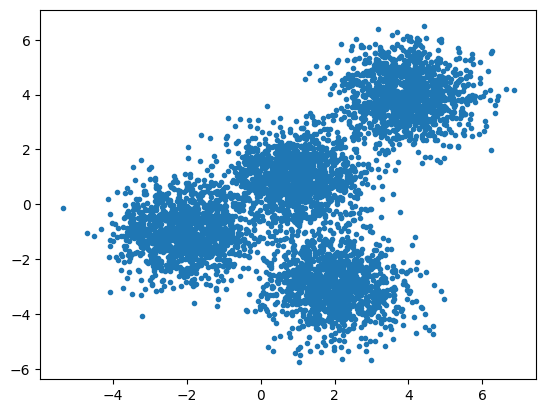

In [4]:
plt.scatter(X[:, 0], X[:, 1], marker='.')
plt.show()

Four groups are visible by eye, though the ones around $(1, 1)$ and $(-2, -1)$
sit close together and overlap at the edges.

### Fitting k-means

`n_clusters=4` because there are four centres; `k-means++` initialisation and 12
restarts as described in section 3.

In [5]:
k_means = KMeans(init = "k-means++", n_clusters = 4, n_init = 12)

In [6]:
k_means.fit(X)

KMeans(n_clusters=4, n_init=12)

`.labels_` holds the cluster each point was assigned to, and `.cluster_centers_`
the final centroids.

In [7]:
k_means_labels = k_means.labels_
k_means_labels

array([0, 3, 3, ..., 1, 0, 0])

In [8]:
k_means_cluster_centers = k_means.cluster_centers_
k_means_cluster_centers

array([[-2.03743147, -0.99782524],
       [ 3.97334234,  3.98758687],
       [ 0.96900523,  0.98370298],
       [ 1.99741008, -3.01666822]])

The four centroids land within about 0.04 of the true centres $(-2, -1)$,
$(4, 4)$, $(1, 1)$ and $(2, -3)$. The cluster *numbers* are arbitrary — k-means
has no way to know which group the generator called "0" — but the positions are
right.

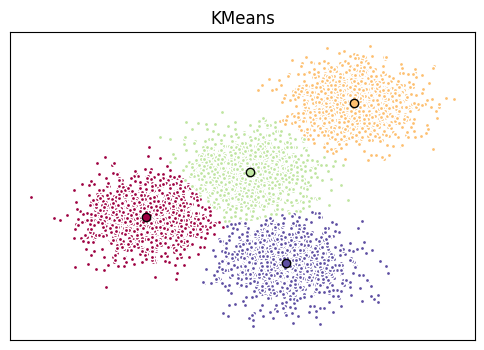

In [9]:
# Initialize the plot with the specified dimensions.
fig = plt.figure(figsize=(6, 4))

# Colors uses a color map, which will produce an array of colors based on
# the number of labels there are. We use set(k_means_labels) to get the
# unique labels.
colors = plt.cm.Spectral(np.linspace(0, 1, len(set(k_means_labels))))

# Create a plot
ax = fig.add_subplot(1, 1, 1)

# For loop that plots the data points and centroids.
# k will range from 0-3, which will match the possible clusters that each
# data point is in.
for k, col in zip(range(len([[4,4], [-2, -1], [2, -3], [1, 1]])), colors):

    # Create a list of all data points, where the data points that are
    # in the cluster (ex. cluster 0) are labeled as true, else they are
    # labeled as false.
    my_members = (k_means_labels == k)

    # Define the centroid, or cluster center.
    cluster_center = k_means_cluster_centers[k]

    # Plots the datapoints with color col.
    ax.plot(X[my_members, 0], X[my_members, 1], 'w', markerfacecolor=col, marker='.')

    # Plots the centroids with specified color, but with a darker outline
    ax.plot(cluster_center[0], cluster_center[1], 'o', markerfacecolor=col,  markeredgecolor='k', markersize=6)

# Title of the plot
ax.set_title('KMeans')

# Remove x-axis ticks
ax.set_xticks(())

# Remove y-axis ticks
ax.set_yticks(())

# Show the plot
plt.savefig('figures/blobs_k4.png', dpi=150, bbox_inches='tight')
plt.show()

### Asking for the wrong number of clusters

The data has four groups. Asking for three shows what k-means does when $k$ is
wrong.

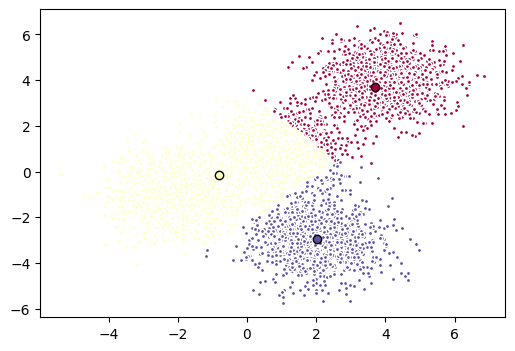

In [10]:
k_means3 = KMeans(init = "k-means++", n_clusters = 3, n_init = 12)
k_means3.fit(X)
fig = plt.figure(figsize=(6, 4))
colors = plt.cm.Spectral(np.linspace(0, 1, len(set(k_means3.labels_))))
ax = fig.add_subplot(1, 1, 1)
for k, col in zip(range(len(k_means3.cluster_centers_)), colors):
    my_members = (k_means3.labels_ == k)
    cluster_center = k_means3.cluster_centers_[k]
    ax.plot(X[my_members, 0], X[my_members, 1], 'w', markerfacecolor=col, marker='.')
    ax.plot(cluster_center[0], cluster_center[1], 'o', markerfacecolor=col,  markeredgecolor='k', markersize=6)
plt.savefig('figures/blobs_k3.png', dpi=150, bbox_inches='tight')
plt.show()

It returns three clusters without complaint. The two well-separated groups, at
$(4, 4)$ and $(2, -3)$, keep a cluster each, and the two groups that sit closest
together — around $(-2, -1)$ and $(1, 1)$ — are merged into one, with a single
centroid between them that describes neither group well.

This is the central weakness of k-means: **it always finds exactly $k$ clusters,
whether or not $k$ clusters exist.** On generated data the mistake is visible.
On real data with eight features, it would not be.

## 5. Customer segmentation

A bank's customer records: 850 customers with demographic and financial
information. The goal is to divide them into groups that share characteristics,
so that each group could be offered different products or treated with a
different level of caution.

In [11]:
import pandas as pd
cust_df = pd.read_csv("data/Cust_Segmentation.csv")
cust_df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,Address,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,NBA001,6.3
1,2,47,1,26,100,4.582,8.218,0.0,NBA021,12.8
2,3,33,2,10,57,6.111,5.802,1.0,NBA013,20.9
3,4,29,2,4,19,0.681,0.516,0.0,NBA009,6.3
4,5,47,1,31,253,9.308,8.908,0.0,NBA008,7.2


In [12]:
cust_df.describe()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
count,850.00000,850.000000,850.000000,850.000000,850.000000,850.000000,850.000000,700.000000,850.000000
mean,425.50000,35.029412,1.710588,8.565882,46.675294,1.576820,3.078773,0.261429,10.171647
std,245.51816,8.041432,0.927784,6.777884,38.543054,2.125843,3.398799,0.439727,6.719441
min,1.00000,20.000000,1.000000,0.000000,13.000000,0.012000,0.046000,0.000000,0.100000
25%,213.25000,29.000000,1.000000,3.000000,24.000000,0.382500,1.045750,0.000000,5.100000
50%,425.50000,34.000000,1.000000,7.000000,35.000000,0.885000,2.003000,0.000000,8.700000
75%,637.75000,41.000000,2.000000,13.000000,55.750000,1.898500,3.903250,1.000000,13.800000
max,850.00000,56.000000,5.000000,33.000000,446.000000,20.561000,35.197000,1.000000,41.300000


In [13]:
cust_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer Id      850 non-null    int64  
 1   Age              850 non-null    int64  
 2   Edu              850 non-null    int64  
 3   Years Employed   850 non-null    int64  
 4   Income           850 non-null    int64  
 5   Card Debt        850 non-null    float64
 6   Other Debt       850 non-null    float64
 7   Defaulted        700 non-null    float64
 8   Address          850 non-null    object 
 9   DebtIncomeRatio  850 non-null    float64
dtypes: float64(4), int64(5), object(1)
memory usage: 66.5+ KB


Two things in this summary matter later:

- `Income` and the two debt columns are in thousands of dollars; `Edu` is an
  education level from 1 to 5; `DebtIncomeRatio` is a percentage.
- `Defaulted` — whether the customer has defaulted on a loan — has only 700
  non-null values. **150 customers have no recorded default status.**

### Pre-processing

`Address` is a code such as `NBA001`, not a quantity. The difference between two
addresses has no meaning as a distance, so it cannot take part in a method built
on distances, and it is dropped.

In [14]:
df = cust_df.drop('Address', axis=1)
df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,5,47,1,31,253,9.308,8.908,0.0,7.2


#### Scaling

Income runs into the hundreds while education runs from 1 to 5. Unscaled,
k-means would group customers almost entirely by income, because income
differences dominate every distance. `StandardScaler` rescales each feature to
mean 0 and standard deviation 1 so that each contributes on equal terms.

`df.values[:,1:]` leaves out `Customer Id`, which identifies a customer and says
nothing about them. `np.nan_to_num` replaces the 150 missing `Defaulted` values
with **0** — that is, it records every customer of unknown status as one who has
not defaulted.

In [15]:
from sklearn.preprocessing import StandardScaler
X = df.values[:,1:]
X = np.nan_to_num(X)
Clus_dataSet = StandardScaler().fit_transform(X)
Clus_dataSet

array([[ 0.74291541,  0.31212243, -0.37878978, ..., -0.59048916,
        -0.52379654, -0.57652509],
       [ 1.48949049, -0.76634938,  2.5737211 , ...,  1.51296181,
        -0.52379654,  0.39138677],
       [-0.25251804,  0.31212243,  0.2117124 , ...,  0.80170393,
         1.90913822,  1.59755385],
       ...,
       [-1.24795149,  2.46906604, -1.26454304, ...,  0.03863257,
         1.90913822,  3.45892281],
       [-0.37694723, -0.76634938,  0.50696349, ..., -0.70147601,
        -0.52379654, -1.08281745],
       [ 2.1116364 , -0.76634938,  1.09746566, ...,  0.16463355,
        -0.52379654, -0.2340332 ]])

### Modeling

Three clusters, with the same initialisation and restarts as before.

In [16]:
clusterNum = 3
k_means = KMeans(init = "k-means++", n_clusters = clusterNum, n_init = 12)
k_means.fit(Clus_dataSet)
labels = k_means.labels_
print(labels)

[0 1 2 0 1 1 0 0 0 1 2 0 0 0 2 0 0 0 1 0 0 0 2 1 1 0 0 0 0 0 0 1 2 0 0 0 2
 2 0 1 2 1 0 1 0 1 0 0 0 0 1 1 2 0 2 2 2 0 0 0 1 0 1 1 0 0 0 2 0 2 0 0 0 0
 0 0 0 0 1 0 0 2 1 0 1 0 0 0 2 2 0 0 2 2 0 0 0 0 2 0 2 1 0 2 2 1 0 0 0 0 0
 0 0 2 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 0 0 0 1 0 0 2
 0 0 0 1 2 0 0 0 0 1 2 2 0 1 0 0 0 0 0 0 0 0 1 0 0 2 0 2 0 0 2 1 2 0 0 1 2
 1 0 0 0 0 0 1 0 2 0 0 0 1 1 0 1 0 2 0 0 2 0 1 0 2 0 0 0 0 0 2 2 1 0 0 2 1
 0 0 0 0 1 0 0 2 0 0 0 0 1 0 0 2 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 2 0 2 0
 0 0 1 0 2 1 2 0 1 0 0 2 0 0 0 0 2 2 2 0 0 0 1 0 0 1 0 1 0 0 1 0 0 0 2 0 0
 2 0 2 1 0 0 0 0 2 0 0 2 2 0 0 0 0 0 0 0 0 2 0 2 1 0 2 0 0 0 2 2 0 0 0 1 2
 0 0 2 0 1 0 0 0 0 0 2 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 1 2 0 2 0 0 0 1 1 0
 2 0 1 2 2 0 0 0 2 0 0 0 0 0 1 0 1 0 0 0 0 2 0 2 0 0 0 1 0 0 0 0 2 0 0 2 2
 1 0 0 0 0 0 2 2 0 1 2 1 0 0 2 0 0 1 1 0 2 0 0 1 0 2 0 1 0 0 0 1 0 0 0 0 1
 0 2 0 0 0 0 1 2 0 0 1 0 2 0 0 1 0 1 0 0 0 0 0 0 0 1 1 0 0 1 0 2 0 0 0 2 0
 2 0 0 0 0 0 1 2 2 0 1 0 

### Profiling the clusters

Each customer's cluster is added to the table, and the average of every feature
within each cluster gives a profile of that group, in the original units.

In [17]:
df["Clus_km"] = labels
df.head(5)

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio,Clus_km
0,1,41,2,6,19,0.124,1.073,0.0,6.3,0
1,2,47,1,26,100,4.582,8.218,0.0,12.8,1
2,3,33,2,10,57,6.111,5.802,1.0,20.9,2
3,4,29,2,4,19,0.681,0.516,0.0,6.3,0
4,5,47,1,31,253,9.308,8.908,0.0,7.2,1


In [18]:
df.groupby('Clus_km').mean()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
Clus_km,,,,,,,,,
0,426.122905,33.817505,1.603352,7.625698,36.143389,0.853128,1.816855,0.000000,7.964991
1,424.408163,43.000000,1.931973,17.197279,101.959184,4.220673,7.954483,0.162393,13.915646
2,424.451807,31.891566,1.861446,3.963855,31.789157,1.576675,2.843355,0.993939,13.994578


Age against income, with each point coloured by cluster and sized by education:

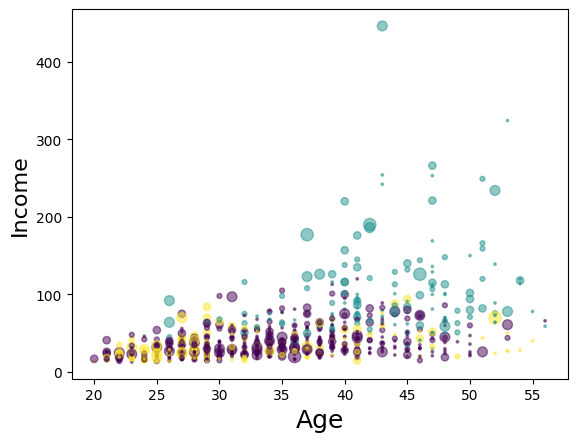

In [19]:
area = np.pi * ( X[:, 1])**2
plt.scatter(X[:, 0], X[:, 3], s=area, c=labels.astype(float), alpha=0.5)
plt.xlabel('Age', fontsize=18)
plt.ylabel('Income', fontsize=16)
plt.savefig('figures/result.png', dpi=150, bbox_inches='tight')
plt.show()

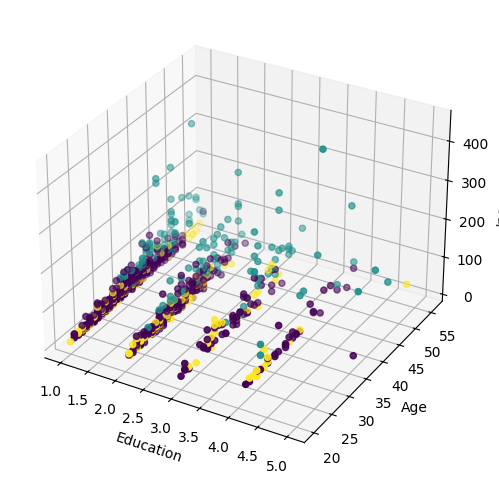

In [20]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.set_xlabel('Education')
ax.set_ylabel('Age')
ax.set_zlabel('Income')

ax.scatter(
    X[:, 1],
    X[:, 0],
    X[:, 3],
    c=labels.astype(float)
)

plt.show()

## 6. What the clusters actually are

The age–income plot already hints at the answer. Cluster 1 (teal) stands apart
at the top, but clusters 0 (purple) and 2 (yellow) lie on top of each other
across the whole range — whatever separates them, it is not age or income.

The profile table says what it is:

| Cluster | Customers | Age | Income ($k) | Years employed | Debt-to-income | Defaulted |
|---|---|---|---|---|---|---|
| 0 | 537 | 33.8 | 36.1 | 7.6 | 7.96% | 0.00 |
| 1 | 147 | 43.0 | 102.0 | 17.2 | 13.92% | 0.16 |
| 2 | 166 | 31.9 | 31.8 | 4.0 | 13.99% | 0.99 |

- **Cluster 1 — established and affluent.** The oldest group, employed longest,
  earning roughly three times the others. Their debts are the largest in
  absolute terms, but their incomes carry them: 16% have defaulted.
- **Cluster 0 — young, modest income, low debt, no defaults.** The largest group
  by far, and the most cautious borrowers, with about half the debt-to-income
  ratio of the other two.
- **Cluster 2 — young, modest income, heavily indebted, defaulted.** Almost the
  same age and income as cluster 0, but newer in work, carrying nearly twice the
  relative debt — and 99% of them have defaulted.

**The split between clusters 0 and 2 is almost exactly the `Defaulted` column**:
0.00 on one side, 0.99 on the other. Age and income barely separate them (34
against 32 years, 36 against 32 thousand dollars). Two consequences follow.

1. **A yes/no column has dominated the result.** After scaling, `Defaulted` takes
   only two values far apart, and that gap is larger than most differences
   between customers on any continuous feature. This is the same problem that
   led to `Address` being dropped — a category does not behave like a distance —
   but `Defaulted` was kept.
2. **The 150 customers of unknown status were placed by a guess.** Filling their
   missing value with 0 recorded them as non-defaulters, which pushes them toward
   cluster 0. The model has not learned that they are safe; it was told so.

Neither makes the segmentation useless — "has defaulted" is a real and
commercially important distinction. But it means the segments are better
described by **credit behaviour** than by age and income alone, and the
grouping of the unknown-status customers should not be trusted.

**Was 3 the right number?** Nothing in this notebook tests it. Section 4 showed
that k-means returns whatever $k$ it is given, so a choice of $k$ on real data
needs evidence of its own.

## 7. References

- Dataset: customer segmentation data (`Cust_Segmentation.csv`), as supplied with
  the course.
- Course: Machine Learning with Python (Jadi), based on the IBM / Cognitive Class
  k-means lab.
- Lloyd, S. P. (1982). *Least Squares Quantization in PCM*. IEEE Transactions on
  Information Theory 28(2), 129–137.
- Arthur, D. and Vassilvitskii, S. (2007). *k-means++: The Advantages of Careful
  Seeding*. Proceedings of SODA 2007.
- [scikit-learn: K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)